# Task 5: Decision Trees and Random Forests

**Objective:** Learn tree-based models for classification and regression, understand overfitting, compare Decision Tree and Random Forest models, analyze feature importance, and evaluate classification models using cross-validation.

## Datasets

- **Wine Recognition Dataset:** Used for classification. It contains 178 samples, 13 numerical features, and 3 classes.
- **Diabetes Dataset:** Used for regression. It contains 442 samples and 10 numerical features.

Both datasets are included in Scikit-learn, so no separate CSV upload is required.

## Tools Used

Python, Pandas, Matplotlib, Scikit-learn, and Graphviz-compatible DOT export.

**Dataset references:**
- [Wine Recognition Dataset – Scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)
- [Diabetes Dataset – Scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)

Run the cells from top to bottom in Google Colab.

In [1]:
# Step-1: Import Required Libraries

import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_wine, load_diabetes
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_graphviz
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

os.makedirs("output_screenshots", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step-2: Load and Explore the Dataset

wine = load_wine(as_frame=True)
df = wine.frame.copy()

X = df.drop("target", axis=1)
y = df["target"]

print("Dataset Shape:", df.shape)
print("Number of Features:", X.shape[1])
print("Target Classes:")
for class_id, class_count in y.value_counts().sort_index().items():
    print(wine.target_names[class_id], ":", class_count)

print("\nDataset Preview (first 5 records):")
display(df.head())

Dataset Shape: (178, 14)
Number of Features: 13
Target Classes:
class_0 : 59
class_1 : 71
class_2 : 48

Dataset Preview (first 5 records):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
# Step-3: Split the Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Samples:", len(y_train))
print("Testing Samples:", len(y_test))

Training Data: (142, 13)
Testing Data: (36, 13)
Training Samples: 142
Testing Samples: 36


In [4]:
# Step-4: Train Decision Trees and Study Overfitting

tree_unrestricted = DecisionTreeClassifier(random_state=42)
tree_unrestricted.fit(X_train, y_train)

tree_limited = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_limited.fit(X_train, y_train)

overfitting_results = pd.DataFrame({
    "Model": ["Decision Tree (unrestricted)", "Decision Tree (max_depth=3)"],
    "Training Accuracy": [
        accuracy_score(y_train, tree_unrestricted.predict(X_train)),
        accuracy_score(y_train, tree_limited.predict(X_train))
    ],
    "Testing Accuracy": [
        accuracy_score(y_test, tree_unrestricted.predict(X_test)),
        accuracy_score(y_test, tree_limited.predict(X_test))
    ]
})

print("Training vs Testing Accuracy:")
display(overfitting_results.round(4))

Training vs Testing Accuracy:


,Model,Training Accuracy,Testing Accuracy
0,Decision Tree (unrestricted),1.000,0.9444
1,Decision Tree (max_depth=3),0.993,0.9444


Graphviz DOT file saved as decision_tree.dot


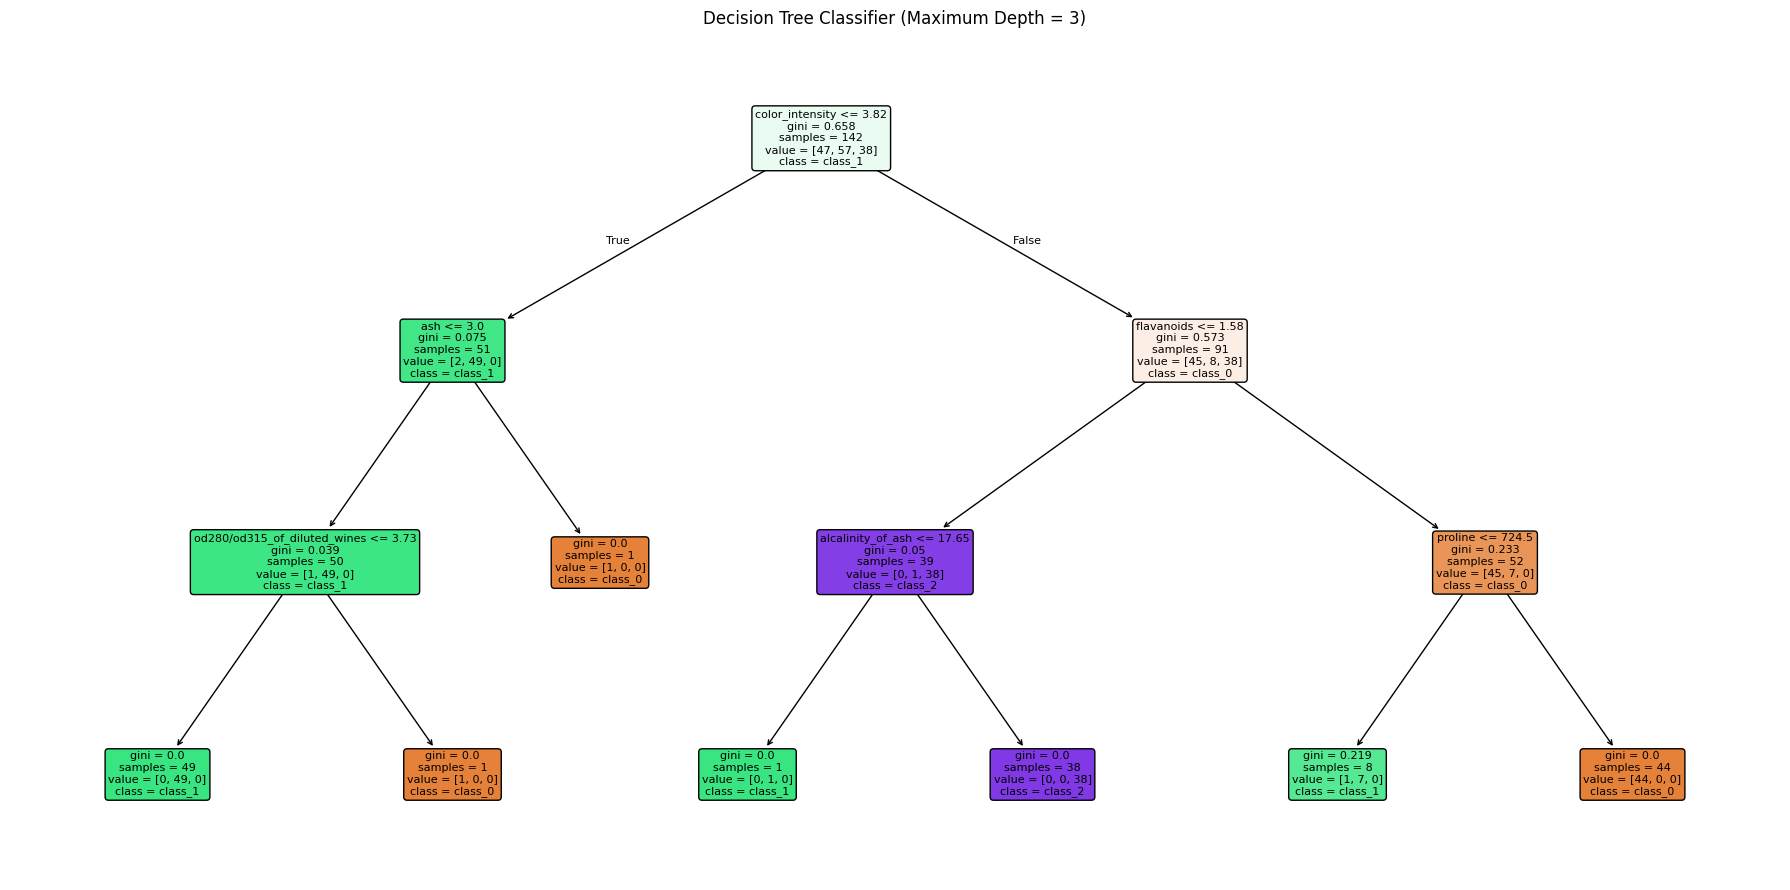

In [5]:
# Step-5: Visualize the Decision Tree and Export Graphviz DOT File

dot_data = export_graphviz(
    tree_limited,
    out_file=None,
    feature_names=X.columns,
    class_names=list(wine.target_names),
    filled=True,
    rounded=True,
    special_characters=True
)

with open("decision_tree.dot", "w", encoding="utf-8") as file:
    file.write(dot_data)

print("Graphviz DOT file saved as decision_tree.dot")

plt.figure(figsize=(18, 9))
plot_tree(
    tree_limited,
    feature_names=X.columns,
    class_names=list(wine.target_names),
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree Classifier (Maximum Depth = 3)")
plt.tight_layout()
plt.savefig("output_screenshots/decision_tree_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Step-6: Train a Random Forest Classifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest.fit(X_train, y_train)

tree_test_accuracy = accuracy_score(y_test, tree_limited.predict(X_test))
forest_test_accuracy = accuracy_score(y_test, random_forest.predict(X_test))

model_comparison = pd.DataFrame({
    "Model": ["Decision Tree (max_depth=3)", "Random Forest (200 trees)"],
    "Training Accuracy": [
        accuracy_score(y_train, tree_limited.predict(X_train)),
        accuracy_score(y_train, random_forest.predict(X_train))
    ],
    "Testing Accuracy": [
        tree_test_accuracy,
        forest_test_accuracy
    ]
})

print("Decision Tree vs Random Forest:")
display(model_comparison.round(4))

Decision Tree vs Random Forest:


,Model,Training Accuracy,Testing Accuracy
0,Decision Tree (max_depth=3),0.993,0.9444
1,Random Forest (200 trees),1.000,1.0000


In [7]:
# Step-7: Evaluate the Random Forest Model

forest_predictions = random_forest.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, forest_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    forest_predictions,
    target_names=list(wine.target_names),
    zero_division=0
))

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



Top 10 Important Features:


,Feature,Importance
9,color_intensity,0.1874
6,flavanoids,0.1684
12,proline,0.1570
0,alcohol,0.1082
10,hue,0.0950
11,od280/od315_of_diluted_wines,0.0899
5,total_phenols,0.0513
4,magnesium,0.0352
1,malic_acid,0.0302
8,proanthocyanins,0.0283


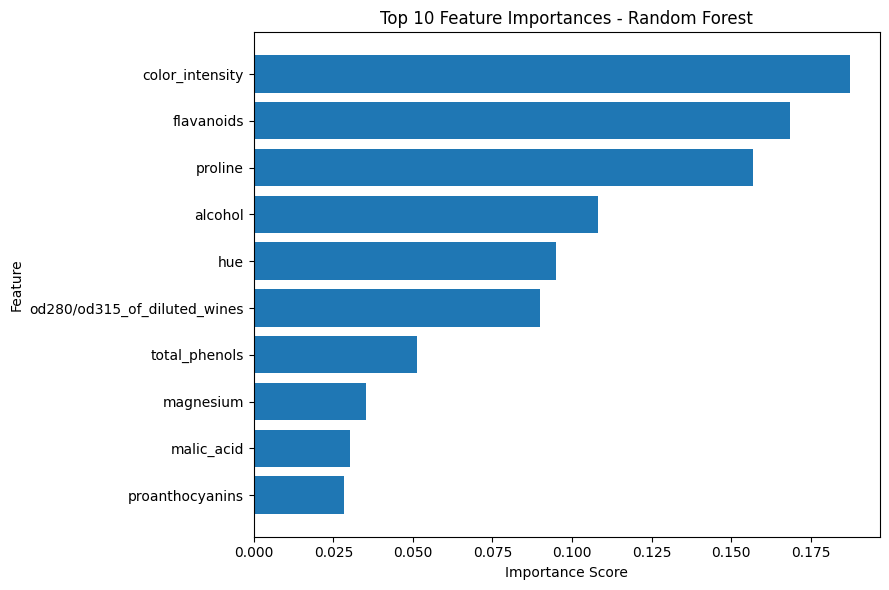

In [8]:
# Step-8: Analyze Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 10 Important Features:")
display(feature_importance.head(10).round(4))

top_features = feature_importance.head(10).sort_values(by="Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Random Forest")
plt.tight_layout()
plt.savefig("output_screenshots/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Step-9: Evaluate Models Using 5-Fold Cross-Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_cv_scores = cross_val_score(
    tree_limited, X_train, y_train,
    cv=cv, scoring="accuracy"
)

forest_cv_scores = cross_val_score(
    random_forest, X_train, y_train,
    cv=cv, scoring="accuracy"
)

cv_results = pd.DataFrame({
    "Model": ["Decision Tree (max_depth=3)", "Random Forest (200 trees)"],
    "Fold 1": [tree_cv_scores[0], forest_cv_scores[0]],
    "Fold 2": [tree_cv_scores[1], forest_cv_scores[1]],
    "Fold 3": [tree_cv_scores[2], forest_cv_scores[2]],
    "Fold 4": [tree_cv_scores[3], forest_cv_scores[3]],
    "Fold 5": [tree_cv_scores[4], forest_cv_scores[4]],
    "Mean Accuracy": [tree_cv_scores.mean(), forest_cv_scores.mean()]
})

print("5-Fold Cross-Validation Results:")
print(cv_results.round(4).to_string(index=False))

print("\nDecision Tree Mean CV Accuracy:", round(tree_cv_scores.mean(), 4))
print("Random Forest Mean CV Accuracy:", round(forest_cv_scores.mean(), 4))

5-Fold Cross-Validation Results:
                      Model  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean Accuracy
Decision Tree (max_depth=3)  0.7931  0.8966  0.9286  0.8929  0.9643         0.8951
  Random Forest (200 trees)  0.9310  1.0000  1.0000  1.0000  0.9643         0.9791

Decision Tree Mean CV Accuracy: 0.8951
Random Forest Mean CV Accuracy: 0.9791


In [10]:
# Step-10: Load the Diabetes Dataset for Regression

diabetes = load_diabetes(as_frame=True)
regression_df = diabetes.frame.copy()

X_reg = regression_df.drop("target", axis=1)
y_reg = regression_df["target"]

print("Regression Dataset Shape:", regression_df.shape)
print("Number of Regression Features:", X_reg.shape[1])
print("\nRegression Dataset Preview:")
print(regression_df.head().T.to_string())

Regression Dataset Shape: (442, 11)
Number of Regression Features: 10

Regression Dataset Preview:
                 0          1           2           3           4
age       0.038076  -0.001882    0.085299   -0.089063    0.005383
sex       0.050680  -0.044642    0.050680   -0.044642   -0.044642
bmi       0.061696  -0.051474    0.044451   -0.011595   -0.036385
bp        0.021872  -0.026328   -0.005670   -0.036656    0.021872
s1       -0.044223  -0.008449   -0.045599    0.012191    0.003935
s2       -0.034821  -0.019163   -0.034194    0.024991    0.015596
s3       -0.043401   0.074412   -0.032356   -0.036038    0.008142
s4       -0.002592  -0.039493   -0.002592    0.034309   -0.002592
s5        0.019907  -0.068332    0.002861    0.022688   -0.031988
s6       -0.017646  -0.092204   -0.025930   -0.009362   -0.046641
target  151.000000  75.000000  141.000000  206.000000  135.000000


In [11]:
# Step-11: Train Decision Tree and Random Forest Regressors

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

tree_regressor = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

forest_regressor = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

tree_regressor.fit(X_reg_train, y_reg_train)
forest_regressor.fit(X_reg_train, y_reg_train)

tree_reg_predictions = tree_regressor.predict(X_reg_test)
forest_reg_predictions = forest_regressor.predict(X_reg_test)

print("Regression training data:", X_reg_train.shape)
print("Regression testing data:", X_reg_test.shape)
print("Both regression models trained successfully!")

Regression training data: (353, 10)
Regression testing data: (89, 10)
Both regression models trained successfully!


In [12]:
# Step-12: Compare Regression Model Performance

regression_results = pd.DataFrame({
    "Model": ["Decision Tree Regressor (max_depth=4)", "Random Forest Regressor (200 trees)"],
    "MAE": [
        mean_absolute_error(y_reg_test, tree_reg_predictions),
        mean_absolute_error(y_reg_test, forest_reg_predictions)
    ],
    "RMSE": [
        mean_squared_error(y_reg_test, tree_reg_predictions) ** 0.5,
        mean_squared_error(y_reg_test, forest_reg_predictions) ** 0.5
    ],
    "R2 Score": [
        r2_score(y_reg_test, tree_reg_predictions),
        r2_score(y_reg_test, forest_reg_predictions)
    ]
})

print("Regression Model Comparison:")
print(regression_results.round(4).to_string(index=False))

Regression Model Comparison:
                                Model     MAE    RMSE  R2 Score
Decision Tree Regressor (max_depth=4) 47.0454 59.7408    0.3264
  Random Forest Regressor (200 trees) 44.2761 54.4612    0.4402


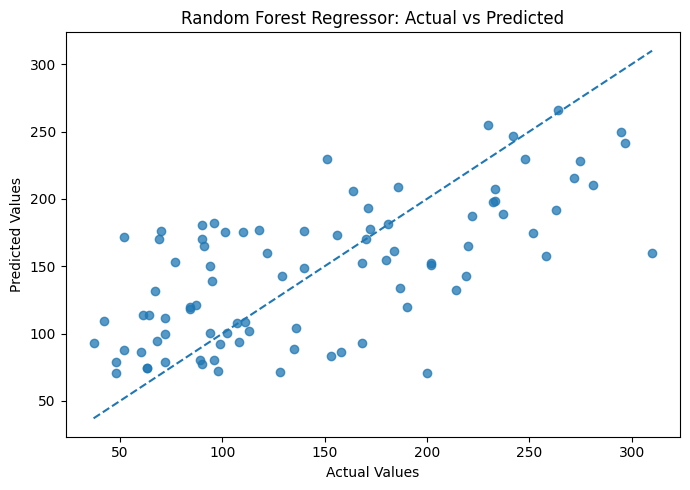

In [13]:
# Step-13: Visualize Actual vs Predicted Regression Values

plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, forest_reg_predictions, alpha=0.75)

lower_value = min(y_reg_test.min(), forest_reg_predictions.min())
upper_value = max(y_reg_test.max(), forest_reg_predictions.max())

plt.plot(
    [lower_value, upper_value],
    [lower_value, upper_value],
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Random Forest Regressor: Actual vs Predicted")
plt.tight_layout()
plt.savefig("output_screenshots/regression_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# Step-14: Final Summary

print("CLASSIFICATION")
print("Decision Tree Test Accuracy:", round(tree_test_accuracy, 4))
print("Random Forest Test Accuracy:", round(forest_test_accuracy, 4))
print("Decision Tree Mean CV Accuracy:", round(tree_cv_scores.mean(), 4))
print("Random Forest Mean CV Accuracy:", round(forest_cv_scores.mean(), 4))

print("\nREGRESSION")
print(regression_results.round(4).to_string(index=False))

print("\nTask 5 completed successfully!")

CLASSIFICATION
Decision Tree Test Accuracy: 0.9444
Random Forest Test Accuracy: 1.0
Decision Tree Mean CV Accuracy: 0.8951
Random Forest Mean CV Accuracy: 0.9791

REGRESSION
                                Model     MAE    RMSE  R2 Score
Decision Tree Regressor (max_depth=4) 47.0454 59.7408    0.3264
  Random Forest Regressor (200 trees) 44.2761 54.4612    0.4402

Task 5 completed successfully!


## Conclusion

This task provided practical experience with Decision Tree and Random Forest models for both classification and regression. The classification section compares model accuracy, examines overfitting, visualizes the tree, identifies important features, and uses 5-fold cross-validation. The regression section compares Decision Tree and Random Forest predictions using MAE, RMSE, and R².

The results are based on the selected built-in datasets and train-test split. They are intended for learning and are not a guarantee of performance on new real-world data.